# Previsão do tempo de espera na fila (Citizen Assist AI)
## Atenção: este notebook usa dados simulados

Os dados abaixo não são reais. Nós geramos esses dados aqui mesmo, no notebook, para imitar
um dia de mutirão de segunda via de documentos (enchentes de 2024 no RS), das 8h às 17h.

O objetivo é comparar dois jeitos de estimar o tempo de espera:
1. Método convencional: `espera = pessoas_na_fila × tempo médio de atendimento`.
2. Método IA (regressão linear): `espera = A × pessoas_na_fila + B × pessoas_no_pico + C`.

Na primeira versão, a IA usava a hora como entrada (`A × fila + B × hora + C`) e previa
−3 min para 1 pessoa. Percebemos que, nos dados, o pico deixa cada pessoa mais lenta, e a hora
entrando como uma reta não representa isso. Por isso trocamos a entrada para pessoas no horário de pico.

No final, o notebook imprime os valores de A, B e C para copiar no `sketch.ino` do ESP32.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

## 1. Gerando os dados simulados

Inventamos estas regras, tentando deixar parecido com um mutirão de verdade:
- São 300 registros, cada um é um momento do dia entre 8h e 17h.
- Os horários de pico são 10h–12h e 14h–16h. No pico a fila é maior (5 a 40 pessoas) e o
  atendimento é mais lento, 3,5 min por pessoa. Fora do pico a fila tem 0 a 20 pessoas
  e o atendimento leva 2,5 min por pessoa. Na média do dia, dá cerca de 3 min por pessoa.
- Somamos um ruído aleatório (desvio de 2 min) para ficar mais realista.

O `np.random.seed(42)` faz os números aleatórios saírem sempre iguais, então o resultado é o mesmo toda vez que rodamos.

In [2]:
np.random.seed(42)
N = 300

# hora do dia em decimal (ex.: 10.5 = 10h30)
hora = np.round(np.random.uniform(8, 17, N), 2)

pico = ((hora >= 10) & (hora < 12)) | ((hora >= 14) & (hora < 16))

# no pico a fila é maior e cada pessoa demora mais
pessoas_na_fila = np.where(pico,
                           np.random.randint(5, 41, N),
                           np.random.randint(0, 21, N))
tempo_por_pessoa = np.where(pico, 3.5, 2.5)

# espera = pessoas x tempo por pessoa + ruído (nunca negativa)
ruido = np.random.normal(0, 2, N)
espera_real_min = np.clip(pessoas_na_fila * tempo_por_pessoa + ruido, 0, None)
espera_real_min = np.round(espera_real_min, 1)

dados = pd.DataFrame({
    "hora": hora,
    "pessoas_na_fila": pessoas_na_fila,
    "espera_real_min": espera_real_min,
})

dados.to_csv("dados_simulados.csv", index=False)
print("Arquivo dados_simulados.csv salvo com", len(dados), "registros (SIMULADOS).")
dados.head()

Arquivo dados_simulados.csv salvo com 300 registros (SIMULADOS).


,hora,pessoas_na_fila,espera_real_min
0,11.37,36,125.6
1,16.56,1,2.6
2,14.59,39,140.1
3,13.39,5,13.7
4,9.40,0,0.4


In [3]:
dados.describe().round(2)

,hora,pessoas_na_fila,espera_real_min
count,300.00,300.00,300.00
mean,12.46,14.69,46.28
std,2.65,10.51,38.65
min,8.05,0.00,0.00
25%,10.16,6.00,16.25
50%,12.60,13.00,34.05
75%,14.81,20.25,71.45
max,16.91,40.00,141.60


## 2. Criando as colunas `pico` e `pessoas_no_pico`

A coluna `pico` vale 1 se a hora está entre 10h–12h ou 14h–16h, e 0 no resto do dia.
A coluna `pessoas_no_pico` é `pessoas_na_fila × pico`: fora do pico ela vale 0, e no pico ela é
igual ao tamanho da fila.

Com isso, a regressão consegue aprender um tempo por pessoa fora do pico e um tempo extra por
pessoa no pico. Essas colunas ficam só na tabela em memória, o arquivo `dados_simulados.csv` não muda.

In [4]:
# mesma regra de pico usada para gerar os dados
dados["pico"] = (((dados["hora"] >= 10) & (dados["hora"] < 12)) |
                 ((dados["hora"] >= 14) & (dados["hora"] < 16))).astype(int)

dados["pessoas_no_pico"] = dados["pessoas_na_fila"] * dados["pico"]

dados.head()

,hora,pessoas_na_fila,espera_real_min,pico,pessoas_no_pico
0,11.37,36,125.6,1,36
1,16.56,1,2.6,0,0
2,14.59,39,140.1,1,39
3,13.39,5,13.7,0,0
4,9.40,0,0.4,0,0


## 3. Separando treino (80%) e teste (20%)

Os dados de treino são os que os métodos usam para aprender. Os de teste ficam guardados para
conferir se a previsão acerta em casos que o método nunca viu.

In [5]:
treino, teste = train_test_split(dados, test_size=0.2, random_state=42)
print("Registros de treino:", len(treino))
print("Registros de teste: ", len(teste))

Registros de treino: 240
Registros de teste:  60


## 4. Método convencional

Calculamos o tempo médio por pessoa no treino (`tempo_medio = soma das esperas / soma das pessoas`)
e depois prevemos `espera = pessoas_na_fila × tempo_medio`. É a mesma conta que o ESP32 faz com a
média dos últimos atendimentos.

In [6]:
tempo_medio = treino["espera_real_min"].sum() / treino["pessoas_na_fila"].sum()
print(f"Tempo médio histórico por pessoa: {tempo_medio:.2f} min")

previsao_convencional = teste["pessoas_na_fila"] * tempo_medio

Tempo médio histórico por pessoa: 3.17 min


## 5. Método IA: regressão linear

A regressão linear procura os números A, B e C que fazem a fórmula

`espera = A × pessoas_na_fila + B × pessoas_no_pico + C`

errar o mínimo possível nos dados de treino.

O A é quanto cada pessoa demora fora do pico, em minutos. O B é quanto cada pessoa demora a mais
no pico (então, no pico, cada pessoa custa A + B). O C é uma constante, que deve ficar perto de 0,
porque com a fila vazia a espera é quase zero.

In [7]:
entradas_treino = treino[["pessoas_na_fila", "pessoas_no_pico"]]
saida_treino = treino["espera_real_min"]

modelo = LinearRegression()
modelo.fit(entradas_treino, saida_treino)

A = modelo.coef_[0]
B = modelo.coef_[1]
C = modelo.intercept_

print(f"A = {A:.4f}   B = {B:.4f}   C = {C:.4f}")
print(f"Fora do pico: {A:.2f} min por pessoa")
print(f"No pico:      {A:.2f} + {B:.2f} = {A + B:.2f} min por pessoa")

previsao_ia = modelo.predict(teste[["pessoas_na_fila", "pessoas_no_pico"]])

A = 2.4998   B = 1.0157   C = -0.2486
Fora do pico: 2.50 min por pessoa
No pico:      2.50 + 1.02 = 3.52 min por pessoa


## 6. Comparação pelo erro médio absoluto (MAE)

O MAE é a média de quanto a previsão errou, em minutos, sem olhar o sinal. Quanto menor, melhor.

In [8]:
mae_convencional = mean_absolute_error(teste["espera_real_min"], previsao_convencional)
mae_ia = mean_absolute_error(teste["espera_real_min"], previsao_ia)

tabela = pd.DataFrame({
    "Método": ["Convencional (média)", "IA (regressão linear)"],
    "MAE (minutos)": [round(mae_convencional, 2), round(mae_ia, 2)],
})
tabela

,Método,MAE (minutos)
0,Convencional (média),7.53
1,IA (regressão linear),1.52


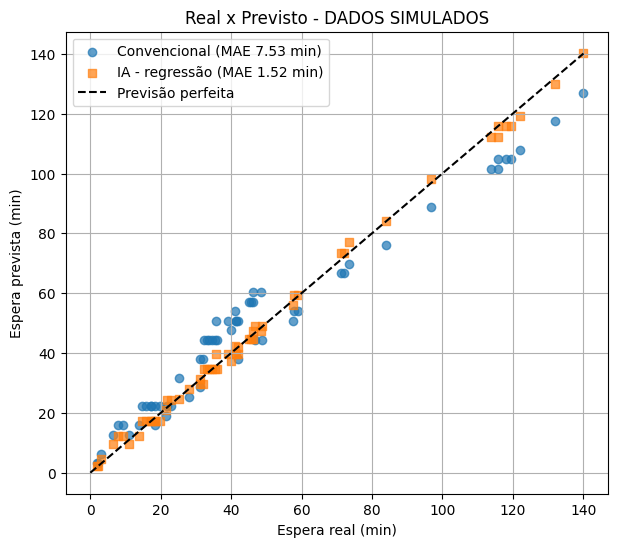

In [9]:
# Real (eixo X) x previsto (eixo Y). Quanto mais perto da linha tracejada, melhor.
plt.figure(figsize=(7, 6))
plt.scatter(teste["espera_real_min"], previsao_convencional,
            label=f"Convencional (MAE {mae_convencional:.2f} min)", alpha=0.7)
plt.scatter(teste["espera_real_min"], previsao_ia,
            label=f"IA - regressão (MAE {mae_ia:.2f} min)", alpha=0.7, marker="s")
maximo = teste["espera_real_min"].max()
plt.plot([0, maximo], [0, maximo], "k--", label="Previsão perfeita")
plt.xlabel("Espera real (min)")
plt.ylabel("Espera prevista (min)")
plt.title("Real x Previsto - DADOS SIMULADOS")
plt.legend()
plt.grid(True)
plt.show()

## 7. Previsões para filas pequenas e grandes

Fizemos uma tabela com a previsão da IA para fila 1, 2, 3 e 10, fora e dentro do pico.
Usamos a mesma regra do ESP32: se tem alguém na fila, a espera mostrada é no mínimo 1 min.

In [10]:
linhas = []
for fila in [1, 2, 3, 10]:
    fora = A * fila + B * (fila * 0) + C
    dentro = A * fila + B * (fila * 1) + C
    linhas.append({
        "Pessoas na fila": fila,
        "Fora do pico (min)": round(max(fora, 1), 1),   # mínimo de 1 min, igual ao ESP32
        "No pico (min)": round(max(dentro, 1), 1),
    })

tabela_previsoes = pd.DataFrame(linhas)

# conferindo que nenhuma previsão ficou negativa
assert (tabela_previsoes[["Fora do pico (min)", "No pico (min)"]] >= 0).all().all()
print("Nenhuma previsão negativa.")
tabela_previsoes

Nenhuma previsão negativa.


,Pessoas na fila,Fora do pico (min),No pico (min)
0,1,2.3,3.3
1,2,4.8,6.8
2,3,7.3,10.3
3,10,24.7,34.9


## 8. Qual método foi melhor e por quê

| Método | Fórmula | MAE no teste (min) |
|---|---|---|
| Convencional (média) | `pessoas × 3,17` | 7,53 |
| IA (regressão linear) | `2,50 × pessoas + 1,02 × pessoas_no_pico − 0,25` | 1,52 |

A IA errou cerca de 6 min a menos em média (≈ 80% menos erro). Mas lembramos que os dados são simulados.

O método convencional usa um único tempo médio (3,17 min/pessoa) para o dia todo. No pico o
atendimento real é 3,5 min/pessoa, então ele erra para menos; fora do pico (2,5 min/pessoa) ele
erra para mais.

A regressão aprendeu A ≈ 2,50 min por pessoa fora do pico e B ≈ 1,02 min a mais por pessoa no pico
(2,50 + 1,02 ≈ 3,52 min). São quase os mesmos valores que usamos para gerar os dados (2,5 e 3,5).
A constante C ≈ −0,25 ficou perto de zero, e por isso não aparecem mais previsões negativas para filas
pequenas (1 pessoa fora do pico ≈ 2,3 min; no pico ≈ 3,3 min). A nossa primeira versão usava a hora
como uma reta (`B × hora`) e não conseguia representar os dois picos separados. Ela errava mais
(MAE 6,03 min) e previa −3 min para 1 pessoa.

Uma observação importante: a IA acerta tanto porque nós geramos os dados com exatamente essa regra
(no pico, mais minutos por pessoa). O erro que sobra (≈ 1,5 min) é basicamente o ruído que colocamos.
Com dados reais de um mutirão, o resultado seria diferente e o modelo teria que ser treinado de novo.

No ESP32, mesmo sem valores negativos, deixamos a regra de mostrar no mínimo 1 minuto quando tem
alguém na fila.

In [11]:
# Linhas prontas para copiar no wokwi/sketch.ino
print("// Copie estas 3 linhas para o sketch.ino:")
print(f"const float COEF_A = {A:.4f};   // min por pessoa fora do pico")
print(f"const float COEF_B = {B:.4f};   // min a mais por pessoa no pico")
print(f"const float COEF_C = {C:.4f};")

// Copie estas 3 linhas para o sketch.ino:
const float COEF_A = 2.4998;   // min por pessoa fora do pico
const float COEF_B = 1.0157;   // min a mais por pessoa no pico
const float COEF_C = -0.2486;
